# 6. A Target That Rewires

> **Overview.** A milestone for pruning: the target network keeps changing which inputs it reads. Does the method stay
> within 10% of LTUs wired like the target network, with low and with high noise?

**Setup.** Notebook 5's method (one hidden layer, growth, search) and target network, which now changes: every 1k steps,
one target connection either flips its weight's sign or, half the time, moves to an input its target LTU did not read,
with a random $\pm 1$ weight. Output noise of std 0.1 or 1. 5 seeds; 500k steps.

Without pruning, with one strike (notebook 1), with two strikes (notebook 5), and with *oracle pruning*, which cuts,
at the same times, the connections to inputs no target LTU reads.

**Milestone.** RMSE against the noiseless targets over the last 100k steps within 10% of the reference's: the same
LTUs wired like the target network, rewired whenever it changes.

In [1]:
import os
from time import perf_counter
from typing import NamedTuple

os.environ['XLA_PYTHON_CLIENT_PREALLOCATE'] = 'false'   # take GPU memory only as needed, so the GPU can be shared
import jax
jax.config.update('jax_platforms', 'cuda')
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import IDBDState, optax_idbd

%matplotlib inline
assert jax.default_backend() == 'gpu'

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [2]:
# --- Problem ---
N_INPUTS = 1000
N_TARGETS = 8                        # target LTUs
N_SOURCES = 10                       # inputs each target LTU reads, drawn at random
N_OUTPUTS = 10
OUTPUT_FAN_IN = 4                    # target LTUs each output reads, drawn at random
NOISE_STDS = (0.1, 1.0)              # observation noise on each output, low and high

# --- Learner ---
STAT_RATE, VAR_FLOOR = 1e-3, 0.01    # standardization of the LTUs
INIT_STEP_SIZE = 1e-4                # Autostep's initial step-size
META_STEP_SIZE, TAU = 0.02, 1e4
N_LTUS = 32
FAST_STEP_SIZE = 3e-2                # initial step-size of a new LTU's input weights
GROW_Z = 6.0                         # an LTU connects an input whose gradient sum is this many RMS above the rest
FAN_IN = 20                          # a new LTU first reads this many inputs
REPLACED = 4                         # LTUs replaced at each search step, those with the smallest sum of |output weights|

# --- Experiment ---
NUM_STEPS = 500_000
WINDOW = 1_000                       # steps per recorded RMSE, between growths, and between changes of the target
N_SEEDS = 5
PERIOD = 10_000                      # steps between search steps, each just after a pruning
LAST, MARGIN = 100_000, 1.1          # milestone: RMSE over the last LAST steps within MARGIN times the reference's

## Target

In [3]:
class Target(NamedTuple):
    w: jax.Array                # (N_TARGETS, N_INPUTS): the target LTUs' weights, +-1 on the inputs they read, 0 elsewhere
    out: jax.Array              # (N_OUTPUTS, N_TARGETS): the outputs' weights, +-1/2 on the target LTUs they read


def make_target(key):
    # Each target LTU reads N_SOURCES inputs and each output OUTPUT_FAN_IN target LTUs, all drawn at random, with
    # random +-1 weights (the outputs' scaled to unit variance).
    read_key, w_key, out_key, out_w_key = jax.random.split(key, 4)
    pick = lambda k, shape, n: jnp.argsort(jnp.argsort(jax.random.uniform(k, shape))) < n   # n random entries per row
    w = jax.random.rademacher(w_key, (N_TARGETS, N_INPUTS), dtype=float) * pick(read_key, (N_TARGETS, N_INPUTS), N_SOURCES)
    out = (jax.random.rademacher(out_w_key, (N_OUTPUTS, N_TARGETS), dtype=float)
           * pick(out_key, (N_OUTPUTS, N_TARGETS), OUTPUT_FAN_IN) / np.sqrt(OUTPUT_FAN_IN))
    return Target(w, out)


def change(target, key):
    # One target connection changes: a random input weight of a random target LTU flips sign or, half the time, moves
    # to a random input that target LTU does not read, with a random +-1 weight.
    unit_key, old_key, new_key, move_key, sign_key = jax.random.split(key, 5)
    unit = jax.random.randint(unit_key, (), 0, N_TARGETS)
    row = target.w[unit]
    old = jnp.argmax(jnp.where(row != 0, jax.random.uniform(old_key, (N_INPUTS,)), -1.0))
    new = jnp.argmax(jnp.where(row == 0, jax.random.uniform(new_key, (N_INPUTS,)), -1.0))
    moved = row.at[old].set(0.0).at[new].set(jax.random.rademacher(sign_key, (), dtype=float))
    row = jnp.where(jax.random.bernoulli(move_key), moved, row.at[old].multiply(-1.0))
    return target._replace(w=target.w.at[unit].set(row))


def sample(target, noise_std, key):
    # One input, and its targets with noise of std noise_std and without.
    x_key, noise_key = jax.random.split(key)
    x = jax.random.normal(x_key, (N_INPUTS,))
    clean = target.out @ jnp.where(target.w @ x > 0, 1.0, -1.0)
    return x, clean + noise_std * jax.random.normal(noise_key, (N_OUTPUTS,)), clean

## Learner

Notebook 5's learner.

In [4]:
OPTIMIZER = optax_idbd(meta_lr=META_STEP_SIZE, init_lr=INIT_STEP_SIZE, autostep=True, tau=TAU,
                       version='squared_inputs')


@jax.custom_vjp
def standardize(bits, mean, error_mean, error_h_mean):
    return (bits - mean) / jnp.sqrt(jnp.maximum(mean * (1 - mean), VAR_FLOOR))


def standardize_fwd(bits, mean, error_mean, error_h_mean):
    variance = mean * (1 - mean)
    scale = jnp.sqrt(jnp.maximum(variance, VAR_FLOOR))
    h = (bits - mean) / scale
    return h, (h, scale, variance > VAR_FLOOR, error_mean, error_h_mean)


def standardize_bwd(saved, g):
    h, scale, unfloored, error_mean, error_h_mean = saved
    return (g - error_mean - jnp.where(unfloored, h * error_h_mean, 0.)) / scale, None, None, None


standardize.defvjp(standardize_fwd, standardize_bwd)


class Stats(NamedTuple):
    # Running statistics of the LTUs, each shaped (N_LTUS,).
    hidden_mean: jax.Array      # firing rate
    error_mean: jax.Array       # means of the error g arriving at each LTU, and of g * h
    error_h_mean: jax.Array


class Net(NamedTuple):
    # w['hidden'] is the LTUs' weights over [inputs, 1 (the bias)], of which each reads those in `reads`; w['output'] is
    # the outputs' weights over [inputs (the linear learner), LTUs, 1].
    w: dict                     # {'hidden': (N_LTUS, N_INPUTS + 1), 'output': (N_OUTPUTS, N_INPUTS + N_LTUS + 1)}
    reads: jax.Array            # shaped like w['hidden']
    added: jax.Array            # whether the LTUs feed the outputs yet
    opt: IDBDState
    stats: Stats
    shadow: jax.Array           # (N_OUTPUTS, N_LTUS): each LTU's shadow weight, +-1 on one output (its parent), 0 elsewhere
    candidates: jax.Array       # (N_LTUS, N_INPUTS): each LTU's sums of dL/dz * x_i since its last new connection


def init_net(key, target):
    # Each pair of LTUs wired like one target LTU in turn: reading its inputs and the bias, with LeCun uniform weights;
    # their shadow weights +1 and -1, on a random output that reads that target LTU. Every other weight 0.
    w_key, out_key = jax.random.split(key)
    assigned = jnp.arange(N_LTUS) // 2 % N_TARGETS
    reads = jnp.append(target.w[assigned] != 0, jnp.ones((N_LTUS, 1), bool), axis=1)
    fan_in = N_SOURCES
    readers = target.out[:, assigned] != 0
    parent = jnp.argmax(jnp.where(readers, jax.random.gumbel(out_key, readers.shape), -jnp.inf), 0)
    shadow = (jnp.arange(N_OUTPUTS)[:, None] == parent) * jnp.where(jnp.arange(N_LTUS) % 2 == 0, 1.0, -1.0)
    w = {'hidden': (jax.random.uniform(w_key, reads.shape, minval=-1.0, maxval=1.0)
                    * jnp.sqrt(3.0 / fan_in) * reads).at[:, -1].set(0.0),
         'output': jnp.zeros((N_OUTPUTS, N_INPUTS + N_LTUS + 1))}
    stats = Stats(jnp.full(N_LTUS, 0.5), jnp.zeros(N_LTUS), jnp.zeros(N_LTUS))
    return Net(w, reads, jnp.array(False), OPTIMIZER.init(w), stats, shadow, jnp.zeros((N_LTUS, N_INPUTS)))


def add(net):
    # The LTUs start feeding the outputs, the step-sizes of their input weights starting at FAST_STEP_SIZE.
    beta = jnp.where(net.reads.at[:, -1].set(False), jnp.log(FAST_STEP_SIZE), net.opt.beta['hidden'])
    return net._replace(added=jnp.array(True), opt=net.opt._replace(beta={**net.opt.beta, 'hidden': beta}))


def rewire(net, key, replaced, parent, signs):
    # Each `replaced` LTU becomes a new LTU. Its shadow weight, +1 or -1 by slot, goes on a random output, its parent.
    # It reads FAN_IN inputs and the bias, the inputs drawn without replacement with probability proportional to the
    # square of the parent's linear weight on each if parent, uniformly otherwise (Gumbel top-k),
    # with LeCun uniform weights, taking the signs of its shadow weight times the parent's linear weights if signs, at
    # step-size FAST_STEP_SIZE. Its output weights are 0, and its statistics, Autostep state and gradient sums fresh.
    out_key, draw_key, w_key = jax.random.split(key, 3)
    sign = jnp.where(jnp.arange(N_LTUS) % 2 == 0, 1.0, -1.0)
    new_parent = jax.random.randint(out_key, (N_LTUS,), 0, N_OUTPUTS)
    shadow = jnp.where(replaced, (jnp.arange(N_OUTPUTS)[:, None] == new_parent) * sign, net.shadow)
    parent_w = shadow.T @ net.w['output'][:, :N_INPUTS]      # each LTU's shadow weight times its parent's linear weights
    scores = jnp.where(parent, jnp.log(parent_w ** 2), 0.0) + jax.random.gumbel(draw_key, parent_w.shape)
    inputs = jnp.argsort(jnp.argsort(-scores)) < FAN_IN
    w = jax.random.uniform(w_key, inputs.shape, minval=-1.0, maxval=1.0) * jnp.sqrt(3.0 / FAN_IN) * inputs
    w = jnp.where(signs, jnp.abs(w) * jnp.sign(parent_w), w)

    where = {'hidden': replaced[:, None],
             'output': jnp.concatenate([jnp.zeros(N_INPUTS, bool), replaced, jnp.zeros(1, bool)])[None]}
    reset = lambda tree, fresh: jax.tree.map(lambda m, a, b: jnp.where(m, a, b), where, fresh, tree)
    zeros = jax.tree.map(jnp.zeros_like, net.w)
    fast = jnp.append(inputs, jnp.zeros((N_LTUS, 1), bool), axis=1)
    beta = {'hidden': jnp.where(fast, jnp.log(FAST_STEP_SIZE), net.opt.init_beta),
            'output': zeros['output'] + net.opt.init_beta}
    opt = net.opt._replace(beta=reset(net.opt.beta, beta), h=reset(net.opt.h, zeros), v=reset(net.opt.v, zeros))
    stats = Stats(*(jnp.where(replaced, fresh, old) for fresh, old in zip((0.5, 0.0, 0.0), net.stats)))
    return net._replace(w=reset(net.w, {'hidden': jnp.append(w, jnp.zeros((N_LTUS, 1)), axis=1),
                                        'output': zeros['output']}),
                        reads=jnp.where(replaced[:, None], jnp.append(inputs, jnp.ones((N_LTUS, 1), bool), axis=1),
                                        net.reads),
                        opt=opt, stats=stats, shadow=shadow, candidates=jnp.where(replaced[:, None], 0.0, net.candidates))


def learn(net, x, y):
    # One online network-Autostep update on half the squared error summed over the outputs, each LTU's shadow weight
    # standing in for its weight to its parent in the backward pass while the real one is smaller than 1 in magnitude.
    # Returns the new network and its prediction on this sample, before learning from it, and adds dL/dz * x_i to each
    # LTU's gradient sums. `probe` is zero; its gradients are the error arriving at each
    # LTU and dL/dz.

    def loss_fn(w, probe):
        b = ltu((w['hidden'] * net.reads) @ jnp.append(x, 1.0) + probe[1])
        mean = net.stats.hidden_mean + STAT_RATE * (jax.lax.stop_gradient(b) - net.stats.hidden_mean)
        h = standardize(b, mean, net.stats.error_mean, net.stats.error_h_mean)
        a = (h + probe[0]) * net.added
        source = jnp.concatenate([x, a, jnp.ones(1)])
        unit_w = w['output'][:, N_INPUTS:-1]
        back = jax.lax.stop_gradient(jnp.where((net.shadow != 0) & (jnp.abs(unit_w) < 1.0), net.shadow, unit_w)) @ a
        prediction = w['output'] @ jax.lax.stop_gradient(source) + back - jax.lax.stop_gradient(back)
        return 0.5 * jnp.sum((prediction - y) ** 2), (jax.lax.stop_gradient(source), jax.lax.stop_gradient(h), mean,
                                                     jax.lax.stop_gradient(prediction))

    (loss, (source, h, mean, prediction)), (grads, (error, dz)) = jax.value_and_grad(loss_fn, (0, 1), has_aux=True)(
        net.w, (jnp.zeros(N_LTUS),) * 2)
    grads = {**grads, 'hidden': grads['hidden'] * net.reads}
    sources = {'hidden': jnp.append(x, 1.0) * net.reads, 'output': jnp.broadcast_to(source, net.w['output'].shape)}
    updates, opt = OPTIMIZER.update((grads, None, sources), net.opt, net.w)
    stats = Stats(mean, net.stats.error_mean + STAT_RATE * (error - net.stats.error_mean),
                  net.stats.error_h_mean + STAT_RATE * (error * h - net.stats.error_h_mean))
    return net._replace(w=jax.tree.map(jnp.add, net.w, updates), opt=opt, stats=stats,
                        candidates=net.candidates + dz[:, None] * x), prediction


def connect(net, new):
    # The LTUs start reading the inputs in `new`, (N_LTUS, N_INPUTS), at weight 0 with step-size FAST_STEP_SIZE.
    new = jnp.append(new, jnp.zeros((N_LTUS, 1), bool), axis=1)
    beta = jnp.where(new, jnp.log(FAST_STEP_SIZE), net.opt.beta['hidden'])
    return net._replace(w={**net.w, 'hidden': jnp.where(new, 0.0, net.w['hidden'])}, reads=net.reads | new,
                        opt=net.opt._replace(beta={**net.opt.beta, 'hidden': beta}))


def grow(net):
    # Each LTU whose largest gradient sum, over the inputs it does not read, is more than GROW_Z times their root mean
    # square connects that input, and restarts its sums.
    unread = ~net.reads[:, :N_INPUTS]
    sums = jnp.where(unread, jnp.abs(net.candidates), 0.0)
    rms = jnp.sqrt(jnp.sum(sums ** 2, 1) / unread.sum(1))
    grows = jnp.max(sums, 1) > GROW_Z * rms
    new = (jnp.arange(N_INPUTS) == jnp.argmax(sums, 1)[:, None]) & grows[:, None]
    return connect(net, new)._replace(candidates=jnp.where(grows[:, None], 0.0, net.candidates))


def cut(net, which):
    # The LTUs stop reading the inputs in `which`, (N_LTUS, N_INPUTS); their weights and Autostep state are reset.
    which = jnp.append(which, jnp.zeros((N_LTUS, 1), bool), axis=1)
    zero = lambda t: {**t, 'hidden': jnp.where(which, 0.0, t['hidden'])}
    beta = jnp.where(which, net.opt.init_beta, net.opt.beta['hidden'])
    opt = net.opt._replace(beta={**net.opt.beta, 'hidden': beta}, h=zero(net.opt.h), v=zero(net.opt.v))
    return net._replace(w=zero(net.w), reads=net.reads & ~which, opt=opt)


def follow(net, target):
    # The reference: each LTU reads the current inputs of the target LTU it is wired like (as in init_net).
    wired = target.w[jnp.arange(N_LTUS) // 2 % N_TARGETS] != 0
    reads = net.reads[:, :N_INPUTS]
    return connect(cut(net, reads & ~wired), wired & ~reads)


## Training

In [5]:
def pick(condition, a, b):
    # a where condition holds, b otherwise, for networks.
    return jax.tree.map(lambda u, v: jnp.where(condition, u, v), a, b)


NONE, ONE_STRIKE, TWO_STRIKES, ORACLE, REFERENCE = range(5)


def train(net, key, target, noise_std, rule):
    # NUM_STEPS online network-Autostep steps on samples from `target`, one of whose connections changes every WINDOW
    # steps. Unless rule is REFERENCE, the LTUs are added as new LTUs (rewired) at step 0; each then grows every WINDOW
    # steps, and every PERIOD steps the LTUs are pruned by `rule`, then the REPLACED LTUs with the smallest sum of
    # |output weights| are replaced by new ones, and the signs of the weights recorded (0 for the new LTUs'). ONE_STRIKE
    # cuts the inputs whose weight changed sign since the last pruning; TWO_STRIKES those whose weight changed sign at
    # each of the last two; ORACLE those no target LTU reads; NONE nothing. The REFERENCE's LTUs are wired like the
    # target network and follow its changes. Returns, for each window, the mean squared error against the noiseless
    # targets, and the mean over the LTUs of the inputs they read that no target LTU reads, at the window's end.
    searched = rule != REFERENCE

    def window(carry, inputs):
        net, target, signs, struck = carry
        index, key = inputs
        wire_key, change_key, key = jax.random.split(key, 3)
        start = index == 0
        target = pick(start, target, change(target, change_key))
        net = pick(start, add(net), net)
        # The first LTUs read random inputs with random signs: their parents have no weights yet.
        net = pick(start & searched, rewire(net, wire_key, jnp.ones(N_LTUS, bool), False, False), net)
        net = pick(rule == REFERENCE, follow(net, target), net)

        def step(net, key):
            x, y, clean = sample(target, noise_std, key)
            net, prediction = learn(net, x, y)
            return net, jnp.mean((prediction - clean) ** 2)

        net, mse = jax.lax.scan(step, net, jax.random.split(key, WINDOW))
        net = pick(searched, grow(net), net)
        weakest = jnp.zeros(N_LTUS, bool).at[jnp.argsort(jnp.abs(net.w['output'][:, N_INPUTS:-1]).sum(0))[:REPLACED]].set(True)
        due = searched & ((index + 1) * WINDOW % PERIOD == 0)
        reads = net.reads[:, :-1]
        dead = reads & ~(target.w != 0).any(0)
        changed = reads & (signs != 0) & (jnp.sign(net.w['hidden'][:, :-1]) != signs)
        which = jnp.where(rule == ORACLE, dead, changed & ((rule == ONE_STRIKE) | ((rule == TWO_STRIKES) & struck)))
        net = pick(due, cut(net, which), net)
        net = pick(due, rewire(net, jax.random.fold_in(wire_key, 1), weakest, True, True), net)
        signs = jnp.where(due, jnp.sign(net.w['hidden'][:, :-1]) * net.reads[:, :-1] * ~weakest[:, None], signs)
        struck = jnp.where(due, changed & (signs != 0), struck)
        return (net, target, signs, struck), (mse.mean(), dead.sum(1).mean())

    n = NUM_STEPS // WINDOW
    signs = jnp.zeros_like(net.w['hidden'][:, :-1])
    return jax.lax.scan(window, (net, target, signs, signs != 0), (jnp.arange(n), jax.random.split(key, n)))[1]


def run(rules):
    # Each rule at each of NOISE_STDS on N_SEEDS seeds, vmapped together; seed s gives every run the same target
    # network, changes and samples. Returns {(rule, noise std): (the RMSE of each window, the inputs read per LTU that
    # no target LTU reads), each shaped (seed, window)}.
    rule, noise, seed = (jnp.array(v) for v in zip(*[(r, n, s) for r in rules for n in NOISE_STDS for s in range(N_SEEDS)]))
    keys = lambda k: jax.random.split(jax.random.PRNGKey(k), N_SEEDS)[seed]
    targets = jax.vmap(make_target)(keys(2))
    nets = jax.vmap(init_net)(keys(0), targets)
    mse, dead = jax.jit(jax.vmap(train))(nets, keys(1), targets, noise, rule)
    shape = (len(rules), len(NOISE_STDS), N_SEEDS, -1)
    mse, dead = np.sqrt(np.asarray(mse)).reshape(shape), np.asarray(dead).reshape(shape)
    return {(r, n): (mse[i, j], dead[i, j]) for i, r in enumerate(rules) for j, n in enumerate(NOISE_STDS)}

## Runs

In [6]:
started = perf_counter()
results = run([NONE, ONE_STRIKE, TWO_STRIKES, ORACLE, REFERENCE])
print(f'{len(results) * N_SEEDS} runs in {perf_counter() - started:.0f}s')

50 runs in 111s


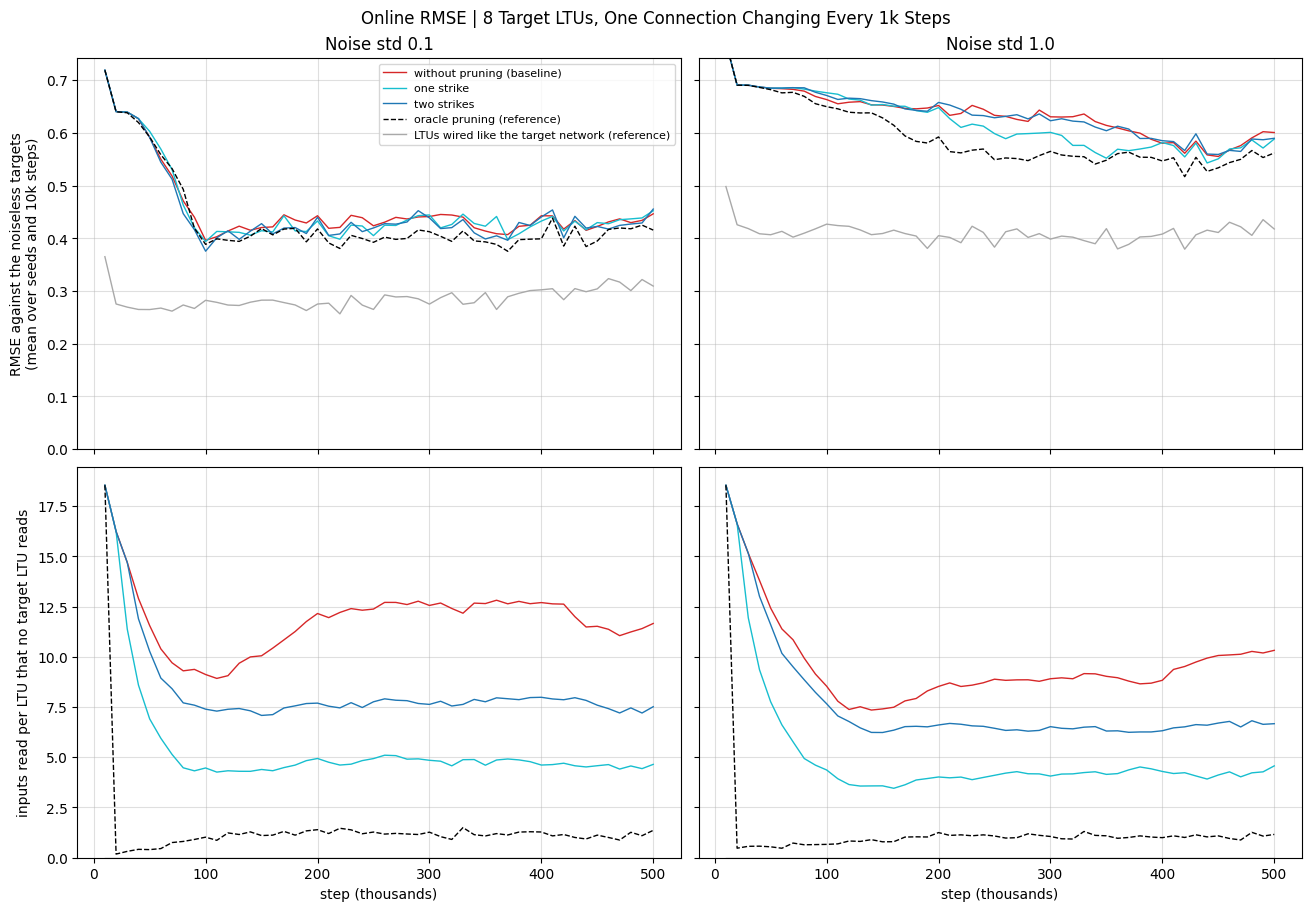

noise 0.1, RMSE over the last 100k steps / the reference's (milestone: <= 1.1): without pruning 1.40, one strike 1.41, two strikes 1.40, oracle pruning 1.34
noise 1.0, RMSE over the last 100k steps / the reference's (milestone: <= 1.1): without pruning 1.39, one strike 1.37, two strikes 1.39, oracle pruning 1.32


In [7]:
BLOCK = 10                                  # windows averaged per plotted point: 10k steps
STEPS = (np.arange(NUM_STEPS // (WINDOW * BLOCK)) + 1) * WINDOW * BLOCK
CURVES = [('without pruning (baseline)', NONE, 'tab:red', '-'), ('one strike', ONE_STRIKE, 'tab:cyan', '-'),
          ('two strikes', TWO_STRIKES, 'tab:blue', '-'), ('oracle pruning (reference)', ORACLE, 'black', '--'),
          ('LTUs wired like the target network (reference)', REFERENCE, 'darkgray', '-')]

fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharex=True, sharey='row', layout='constrained')
for column, noise in enumerate(NOISE_STDS):
    for label, rule, color, ls in CURVES:
        for row in range(2):
            curve = results[rule, noise][row].mean(0).reshape(-1, BLOCK).mean(1)
            axes[row, column].plot(STEPS / 1000, curve, color=color, ls=ls, lw=1, label=label)
    axes[0, column].set(title=f'Noise std {noise}', ylim=(0, None))
    axes[1, column].set(xlabel='step (thousands)', ylim=(0, None))
for ax in axes.flat:
    ax.grid(alpha=0.4)
axes[0, 0].legend(fontsize=8)
axes[0, 0].set_ylabel('RMSE against the noiseless targets\n(mean over seeds and 10k steps)')
axes[1, 0].set_ylabel('inputs read per LTU that no target LTU reads')
fig.suptitle(f'Online RMSE | {N_TARGETS} Target LTUs, One Connection Changing Every {WINDOW // 1000}k Steps')
plt.show()

last = LAST // WINDOW
for noise in NOISE_STDS:
    reference = results[REFERENCE, noise][0][:, -last:].mean()
    print(f'noise {noise}, RMSE over the last {LAST // 1000}k steps / the reference\'s (milestone: <= {MARGIN}): '
          + ', '.join(f'{label.split(" (")[0]} {results[rule, noise][0][:, -last:].mean() / reference:.2f}'
                      for label, rule, *_ in CURVES[:-1]))

## Results

No rule reaches the milestone, and neither does oracle pruning: it ends 34% above the reference at noise 0.1 and 32% at
noise 1, against 40% and 39% without pruning. So the gap is not pruning's. Without pruning, wrong connections stop
piling up at about 12 per LTU, since search replaces the LTUs that hold them, and they cost only about 5%. The method
most likely falls behind because growth does not find the inputs that target connections move to as quickly as they
move (not checked; with notebook 5's slower changes, which move no inputs, it ends near the reference).